<a href="https://colab.research.google.com/github/youngbean0519/Self-Project/blob/main/notebooks/12_2_error_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path
import hashlib
import json
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    hamming_loss,
    precision_recall_fscore_support,
)
from IPython.display import display

BASE = Path("/content/drive/MyDrive/26_KOTE")
INPUT = BASE / "artifacts/week12_comparison"
OUTPUT = BASE / "artifacts/week12-2_analysis"
TABLES = OUTPUT / "tables"
FIGURES = OUTPUT / "figures"
for folder in [OUTPUT, TABLES, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

# 사전 정의한 기술통계 구간. 테스트 결과를 보고 경계를 변경하지 않는다.
RARE_MAX = 500
MEDIUM_MAX = 2000
EXAMPLES_PER_CATEGORY = 5
RANDOM_SEED = 42

# 숫자/영문 축을 사용해 한글 폰트 설치 없이 그림을 만든다.
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def save_table(frame, name):
    frame.to_csv(TABLES / name, index=False, encoding="utf-8-sig")

def save_figure(fig, stem):
    fig.savefig(FIGURES / f"{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGURES / f"{stem}.svg", bbox_inches="tight")
    plt.show()
    plt.close(fig)

def file_hash(path):
    h = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

print("CPU 분석: PyTorch/Transformers 설치 불필요")
print("입력:", INPUT)
print("출력:", OUTPUT)


CPU 분석: PyTorch/Transformers 설치 불필요
입력: /content/drive/MyDrive/26_KOTE/artifacts/week12_comparison
출력: /content/drive/MyDrive/26_KOTE/artifacts/week12-2_analysis


In [ ]:
required = [INPUT / "frozen_selection.json", INPUT / "test_samples.tsv"]
missing = [str(path) for path in required if not path.is_file()]
assert not missing, "12주차 7번 결과가 필요합니다: " + ", ".join(missing)

frozen = read_json(INPUT / "frozen_selection.json")
LABEL_NAMES = list(frozen["labels"])
NUM_LABELS = len(LABEL_NAMES)
assert NUM_LABELS == 44
MODELS = list(frozen["models"])
ENSEMBLE = frozen["ensemble_name"]
ALPHA = float(frozen["alpha_kobert"])
assert all(name in MODELS for name in ["kobert", "koelectra", ENSEMBLE])

samples = pd.read_csv(
    INPUT / "test_samples.tsv",
    sep="\t",
    dtype={"id": str},
    keep_default_na=False,
)
assert samples["id"].is_unique
sample_ids = samples["id"].to_numpy(dtype=str)

def labels_from_text(values):
    result = np.zeros((len(values), NUM_LABELS), dtype=bool)
    for i, value in enumerate(values):
        for item in str(value).split(","):
            if item.strip():
                label_id = int(item.strip())
                assert 0 <= label_id < NUM_LABELS
                result[i, label_id] = True
    return result

Y = labels_from_text(samples["labels"])
SCORES, PREDS = {}, {}
input_hashes = {}
for name in MODELS:
    path = INPUT / f"{name}_test_predictions.npz"
    assert path.is_file(), f"12주차 테스트 출력 누락: {path}"
    input_hashes[path.name] = file_hash(path)
    with np.load(path, allow_pickle=True) as data:
        ids = data["ids"].astype(str)
        assert len(np.unique(ids)) == len(ids)
        assert set(ids) == set(sample_ids), f"{name}: 샘플 ID 불일치"
        assert data["label_names"].astype(str).tolist() == LABEL_NAMES
        order = pd.Index(ids).get_indexer(sample_ids)
        scores = data["scores"][order]
        labels = data["labels"][order]
        assert np.isin(labels, [0, 1]).all()
        assert np.array_equal(labels.astype(bool), Y)
        assert scores.shape == Y.shape and np.isfinite(scores).all()
        threshold = np.asarray(frozen["models"][name]["threshold"])
        pred = scores >= threshold
        if "predictions" in data:
            assert np.array_equal(data["predictions"][order], pred)
        SCORES[name] = scores
        PREDS[name] = pred

assert np.allclose(
    SCORES[ENSEMBLE],
    ALPHA * SCORES["kobert"] + (1 - ALPHA) * SCORES["koelectra"],
    rtol=1e-5,
    atol=1e-6,
)
manifest = {
    "python": sys.version,
    "platform": platform.platform(),
    "input_sha256": input_hashes,
    "frozen_selection_sha256": file_hash(INPUT / "frozen_selection.json"),
    "rare_max": RARE_MAX,
    "medium_max": MEDIUM_MAX,
    "random_seed": RANDOM_SEED,
    "models": MODELS,
    "label_names": LABEL_NAMES,
}
(OUTPUT / "analysis_manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print("샘플 수:", len(Y), "레이블 수:", NUM_LABELS)
print("고정 앙상블 비중: KoBERT", ALPHA)


샘플 수: 5000 레이블 수: 44
고정 앙상블 비중: KoBERT 0.25


,model,micro_f1,macro_f1,hamming_loss,ap_micro,exact_match
0,lr,0.510730,0.361891,0.201264,0.519464,0.0026
1,svm,0.481016,0.382939,0.218709,0.485481,0.0006
2,textcnn,0.565435,0.441041,0.174586,0.598028,0.0044
3,bilstm,0.582669,0.465671,0.159741,0.628373,0.0064
4,kobert,0.618132,0.510164,0.148823,0.666337,0.0074
5,koelectra,0.630519,0.528922,0.140436,0.687325,0.0104
6,ensemble_kobert_0.25,0.637075,0.530911,0.137955,0.697456,0.0086


12주차 결과와 일치
보조 결과: 없음 열만 제외, 문장은 유지


,model,micro_f1,macro_f1,hamming_loss,ap_micro,exact_match
0,lr,0.513807,0.363474,0.201786,0.522716,0.0028
1,svm,0.484314,0.384909,0.218433,0.489036,0.0006
2,textcnn,0.568418,0.441431,0.173749,0.601378,0.0044
3,bilstm,0.585571,0.466671,0.159428,0.631621,0.0066
4,kobert,0.620339,0.510749,0.148935,0.668892,0.0076
5,koelectra,0.632655,0.529408,0.140423,0.689829,0.0106
6,ensemble_kobert_0.25,0.639141,0.531265,0.138009,0.699872,0.0090


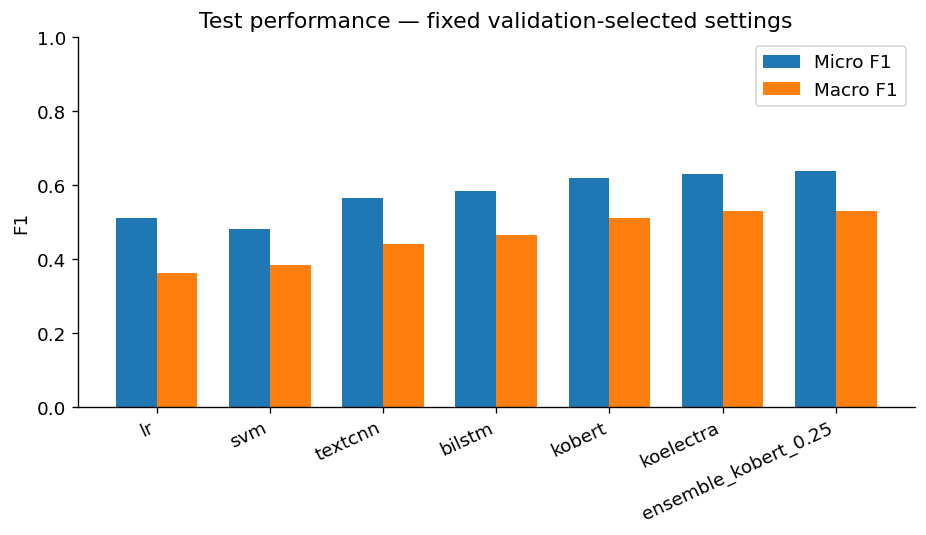

In [ ]:
def evaluate(y, scores, pred):
    return {
        "micro_f1": float(f1_score(y, pred, average="micro", zero_division=0)),
        "macro_f1": float(f1_score(y, pred, average="macro", zero_division=0)),
        "hamming_loss": float(hamming_loss(y, pred)),
        "ap_micro": float(average_precision_score(y, scores, average="micro")),
        "exact_match": float((y == pred).all(axis=1).mean()),
    }

summary = pd.DataFrame([
    {"model": name, **evaluate(Y, SCORES[name], PREDS[name])}
    for name in MODELS
])
save_table(summary, "overall_test_metrics.csv")
display(summary.round(6))
old_path = INPUT / "test_metrics.csv"
if old_path.exists():
    old = pd.read_csv(old_path).set_index("model")
    for row in summary.to_dict("records"):
        for metric in ["micro_f1", "macro_f1", "hamming_loss", "ap_micro"]:
            assert np.isclose(row[metric], old.loc[row["model"], metric], atol=1e-6)
    print("12주차 결과와 일치")

no_emotion = [i for i, label in enumerate(LABEL_NAMES) if label == "없음"]
if no_emotion:
    keep = np.ones(NUM_LABELS, dtype=bool)
    keep[no_emotion] = False
    auxiliary = pd.DataFrame([
        {"model": name, **evaluate(Y[:, keep], SCORES[name][:, keep], PREDS[name][:, keep])}
        for name in MODELS
    ])
    save_table(auxiliary, "auxiliary_43_labels_without_no_emotion.csv")
    print("보조 결과: 없음 열만 제외, 문장은 유지")
    display(auxiliary.round(6))

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(MODELS))
ax.bar(x - 0.18, summary.micro_f1, width=0.36, label="Micro F1")
ax.bar(x + 0.18, summary.macro_f1, width=0.36, label="Macro F1")
ax.set_xticks(x, MODELS, rotation=25, ha="right")
ax.set_ylabel("F1"); ax.set_ylim(0, 1); ax.legend()
ax.set_title("Test performance — fixed validation-selected settings")
save_figure(fig, "01_overall_performance")


,model,label_id,label,test_support,predicted,precision,recall,f1,TP,FP,FN
294,ensemble_kobert_0.25,30,죄책감,84,1,0.000000,0.000000,0.000000,0,1,84
281,ensemble_kobert_0.25,17,부끄러움,306,12,0.166667,0.006536,0.012579,2,10,304
289,ensemble_kobert_0.25,25,패배/자기혐오,208,70,0.400000,0.134615,0.201439,28,42,180
290,ensemble_kobert_0.25,26,귀찮음,290,133,0.360902,0.165517,0.226950,48,85,242
282,ensemble_kobert_0.25,18,공포/무서움,164,69,0.434783,0.182927,0.257511,30,39,134
299,ensemble_kobert_0.25,35,부담/안_내킴,606,389,0.377892,0.242574,0.295477,147,242,459
300,ensemble_kobert_0.25,36,서러움,263,203,0.354680,0.273764,0.309013,72,131,191
283,ensemble_kobert_0.25,19,절망,472,400,0.402500,0.341102,0.369266,161,239,311
275,ensemble_kobert_0.25,11,비장함,416,291,0.474227,0.331731,0.390382,138,153,278
273,ensemble_kobert_0.25,9,우쭐댐/무시함,743,629,0.437202,0.370121,0.400875,275,354,468


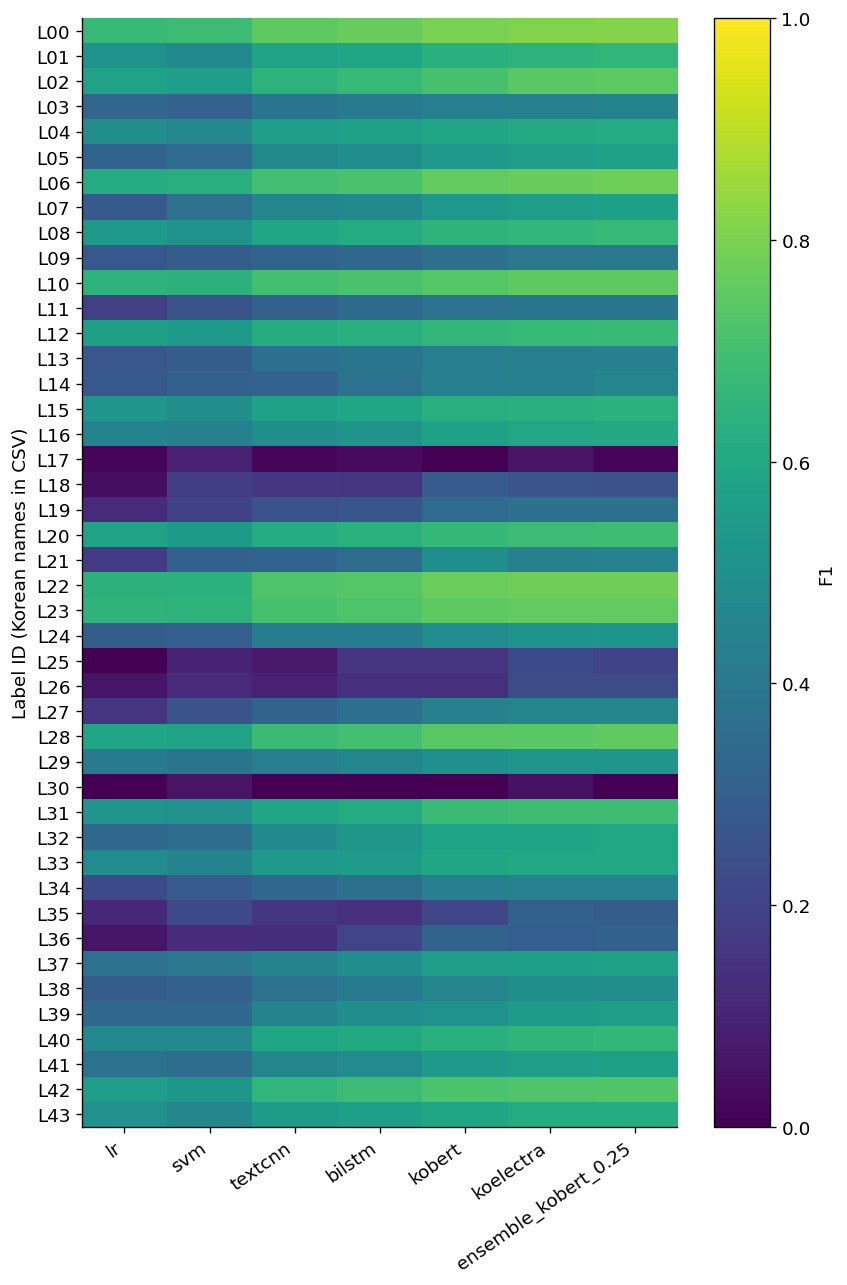

In [ ]:
label_frames = []
for name in MODELS:
    pred = PREDS[name]
    precision, recall, f1, support = precision_recall_fscore_support(
        Y, pred, average=None, zero_division=0,
    )
    label_frames.append(pd.DataFrame({
        "model": name,
        "label_id": np.arange(NUM_LABELS),
        "label": LABEL_NAMES,
        "test_support": support,
        "predicted": pred.sum(axis=0),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "TP": (Y & pred).sum(axis=0),
        "FP": (~Y & pred).sum(axis=0),
        "FN": (Y & ~pred).sum(axis=0),
    }))
label_results = pd.concat(label_frames, ignore_index=True)
save_table(label_results, "labelwise_all_models.csv")
f1_matrix = label_results.pivot(index="label_id", columns="model", values="f1")
f1_matrix = f1_matrix.reindex(columns=MODELS)
f1_export = f1_matrix.copy()
f1_export.insert(0, "label", LABEL_NAMES)
save_table(f1_export.reset_index(), "labelwise_f1_matrix.csv")

focus = ["kobert", "koelectra", ENSEMBLE]
display(label_results.loc[label_results.model == ENSEMBLE].sort_values("f1").head(10))
fig, ax = plt.subplots(figsize=(8, 12))
im = ax.imshow(f1_matrix.to_numpy(), aspect="auto", vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(np.arange(len(MODELS)), MODELS, rotation=35, ha="right")
ax.set_yticks(np.arange(NUM_LABELS), [f"L{i:02d}" for i in range(NUM_LABELS)])
ax.set_ylabel("Label ID (Korean names in CSV)")
fig.colorbar(im, ax=ax, label="F1")
save_figure(fig, "02_labelwise_f1")


,frequency_group,model,label_count,test_positives,micro_f1,macro_f1
0,medium,lr,3,456,0.0128,0.0118
1,medium,svm,3,456,0.1218,0.1123
2,medium,textcnn,3,456,0.0895,0.0753
3,medium,bilstm,3,456,0.1295,0.1016
4,medium,kobert,3,456,0.1834,0.1469
5,medium,koelectra,3,456,0.2151,0.1784
6,medium,ensemble_kobert_0.25,3,456,0.1946,0.1530
7,frequent,lr,41,39195,0.5133,0.3875
8,frequent,svm,41,39195,0.4836,0.4027
9,frequent,textcnn,41,39195,0.5682,0.4678


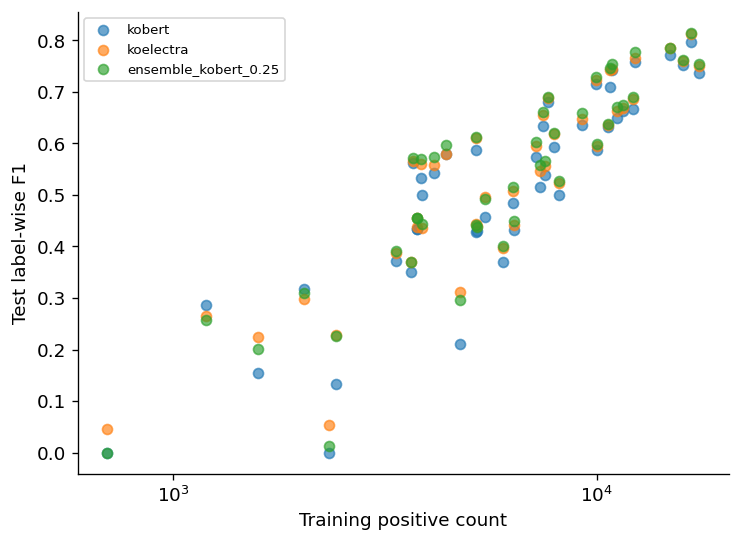

In [ ]:
train_path = BASE / "data/train.tsv"
assert train_path.is_file(), "학습 레이블 빈도 분석에는 train.tsv가 필요합니다."
train = pd.read_csv(
    train_path, sep="\t", header=None,
    names=["id", "text", "labels"], keep_default_na=False,
)
train_y = labels_from_text(train["labels"])
frequency = train_y.sum(axis=0)
groups = np.where(
    frequency <= RARE_MAX, "rare",
    np.where(frequency <= MEDIUM_MAX, "medium", "frequent"),
)
frequency_table = pd.DataFrame({
    "label_id": np.arange(NUM_LABELS),
    "label": LABEL_NAMES,
    "train_support": frequency,
    "frequency_group": groups,
})
save_table(frequency_table, "training_label_frequency.csv")
label_results = label_results.merge(frequency_table, on=["label_id", "label"])
save_table(label_results, "labelwise_with_training_frequency.csv")
group_rows = []
for group in ["rare", "medium", "frequent"]:
    mask = groups == group
    if not mask.any():
        continue
    for name in MODELS:
        row = {
            "frequency_group": group,
            "model": name,
            "label_count": int(mask.sum()),
            "test_positives": int(Y[:, mask].sum()),
        }
        row["micro_f1"] = float(f1_score(
            Y[:, mask], PREDS[name][:, mask], average="micro", zero_division=0,
        ))
        row["macro_f1"] = float(f1_score(
            Y[:, mask], PREDS[name][:, mask], average="macro", zero_division=0,
        ))
        group_rows.append(row)
frequency_results = pd.DataFrame(group_rows)
save_table(frequency_results, "frequency_group_performance.csv")
display(frequency_results.round(4))

correlations = []
fig, ax = plt.subplots(figsize=(7, 5))
for name in focus:
    frame = label_results.loc[label_results.model == name].sort_values("label_id")
    ax.scatter(frame.train_support, frame.f1, alpha=0.65, label=name)
    # 순위 상관: 동점에는 평균 순위 사용
    rho = frame.train_support.rank().corr(frame.f1.rank())
    correlations.append({"model": name, "spearman_rho": rho})
ax.set_xscale("symlog", linthresh=1)
ax.set_xlabel("Training positive count")
ax.set_ylabel("Test label-wise F1"); ax.legend(fontsize=8)
save_figure(fig, "03_frequency_vs_f1")
save_table(pd.DataFrame(correlations), "frequency_f1_rank_correlation.csv")


,group,model,sentences,active_labels,micro_f1,macro_f1_active,exact_match,hamming_loss
0,1,lr,38,11,0.1400,0.2410,0.0000,0.2057
1,1,svm,38,11,0.1327,0.2594,0.0000,0.2111
2,1,textcnn,38,11,0.1889,0.3945,0.0526,0.1746
3,1,bilstm,38,11,0.2152,0.4604,0.0263,0.1483
4,1,kobert,38,11,0.2657,0.4528,0.0526,0.1256
5,1,koelectra,38,11,0.2868,0.5369,0.1053,0.1130
6,1,ensemble_kobert_0.25,38,11,0.2815,0.5135,0.1053,0.1160
7,2,lr,115,37,0.2381,0.2060,0.0000,0.2024
8,2,svm,115,37,0.2325,0.1965,0.0000,0.1996
9,2,textcnn,115,37,0.2869,0.2339,0.0000,0.1769


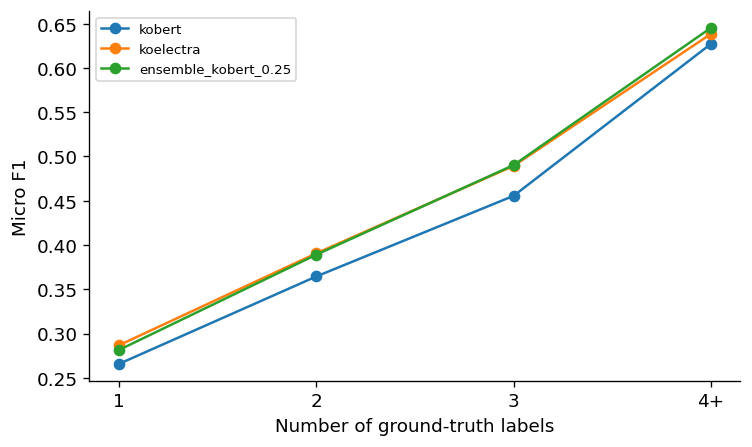

In [ ]:
cardinality = Y.sum(axis=1)
complexity = np.where(
    cardinality == 0, "0", np.where(cardinality >= 4, "4+", cardinality.astype(str)),
)
char_lengths = samples.text.astype(str).str.len().to_numpy()
length_groups = np.where(
    char_lengths <= 50, "0-50", np.where(char_lengths <= 100, "51-100", "101+"),
)

def subgroup_report(group_values, group_order):
    rows = []
    for group in group_order:
        mask = group_values == group
        if not mask.any():
            continue
        y = Y[mask]
        active = y.sum(axis=0) > 0
        for name in MODELS:
            pred = PREDS[name][mask]
            rows.append({
                "group": group,
                "model": name,
                "sentences": int(mask.sum()),
                "active_labels": int(active.sum()),
                "micro_f1": float(f1_score(y, pred, average="micro", zero_division=0)),
                "macro_f1_active": float(f1_score(
                    y[:, active], pred[:, active], average="macro", zero_division=0,
                )) if active.any() else np.nan,
                "exact_match": float((y == pred).all(axis=1).mean()),
                "hamming_loss": float((y != pred).mean()),
            })
    return pd.DataFrame(rows)

complexity_results = subgroup_report(complexity, ["0", "1", "2", "3", "4+"])
length_results = subgroup_report(length_groups, ["0-50", "51-100", "101+"])
save_table(complexity_results, "emotion_cardinality_performance.csv")
save_table(length_results, "character_length_performance.csv")
display(complexity_results.round(4))
fig, ax = plt.subplots(figsize=(7, 4))
for name in focus:
    frame = complexity_results.loc[complexity_results.model == name]
    ax.plot(frame.group, frame.micro_f1, marker="o", label=name)
ax.set_xlabel("Number of ground-truth labels")
ax.set_ylabel("Micro F1"); ax.legend(fontsize=8)
save_figure(fig, "04_multilabel_complexity")


In [ ]:
b = PREDS["kobert"]
e = PREDS["koelectra"]
a = PREDS[ENSEMBLE]
b_correct = b == Y
e_correct = e == Y
pair_masks = {
    "both_correct": b_correct & e_correct,
    "kobert_only_correct": b_correct & ~e_correct,
    "koelectra_only_correct": ~b_correct & e_correct,
    "both_wrong": ~b_correct & ~e_correct,
}
overlap_rows = []
for scope, mask in [
    ("all", np.ones_like(Y)), ("positive_truth", Y), ("negative_truth", ~Y),
]:
    denominator = int(mask.sum())
    for category, pair_mask in pair_masks.items():
        count = int((mask & pair_mask).sum())
        overlap_rows.append({
            "scope": scope, "category": category, "count": count,
            "percent": 100 * count / denominator if denominator else np.nan,
        })
overlap = pd.DataFrame(overlap_rows)
save_table(overlap, "transformer_error_overlap.csv")
display(overlap.round(3))

transition_masks = {}
change_rows = []
for name in ["kobert", "koelectra"]:
    pred = PREDS[name]
    masks = {
        "FN_to_TP": Y & ~pred & a,
        "FP_to_TN": ~Y & pred & ~a,
        "TP_to_FN": Y & pred & ~a,
        "TN_to_FP": ~Y & ~pred & a,
    }
    transition_masks[name] = masks
    for change, mask in masks.items():
        change_rows.append({
            "baseline": name, "change": change,
            "decisions": int(mask.sum()),
            "sentences": int(mask.any(axis=1).sum()),
        })
changes = pd.DataFrame(change_rows)
save_table(changes, "ensemble_improvements_and_regressions.csv")
display(changes)

confusion_rows = []
for name in focus:
    pred = PREDS[name]
    confusion_rows.append({
        "model": name,
        "TP": int((Y & pred).sum()),
        "FP": int((~Y & pred).sum()),
        "FN": int((Y & ~pred).sum()),
        "micro_f1": float(f1_score(Y, pred, average="micro", zero_division=0)),
    })
save_table(pd.DataFrame(confusion_rows), "transformer_confusion_counts.csv")

gains = f1_export.reset_index()[["label_id", "label"]].copy()
for name in focus:
    gains[name] = f1_matrix[name].to_numpy()
gains["ensemble_minus_kobert"] = gains[ENSEMBLE] - gains["kobert"]
gains["ensemble_minus_koelectra"] = gains[ENSEMBLE] - gains["koelectra"]
save_table(gains, "ensemble_labelwise_gains.csv")
print("KoELECTRA 대비 감정별 F1 변화 (해석용, 모델 재선택 금지)")
display(gains.sort_values("ensemble_minus_koelectra", ascending=False).head(8))
display(gains.sort_values("ensemble_minus_koelectra").head(8))


,scope,category,count,percent
0,all,both_correct,178631,81.196
1,all,kobert_only_correct,8628,3.922
2,all,koelectra_only_correct,10473,4.760
3,all,both_wrong,22268,10.122
4,positive_truth,both_correct,23375,58.952
5,positive_truth,kobert_only_correct,3124,7.879
6,positive_truth,koelectra_only_correct,2987,7.533
7,positive_truth,both_wrong,10165,25.636
8,negative_truth,both_correct,155256,86.086
9,negative_truth,kobert_only_correct,5504,3.052


,baseline,change,decisions,sentences
0,kobert,FN_to_TP,2478,1569
1,kobert,FP_to_TN,6351,2987
2,kobert,TP_to_FN,2339,1597
3,kobert,TN_to_FP,4099,2262
4,koelectra,FN_to_TP,787,687
5,koelectra,FP_to_TN,1414,1095
6,koelectra,TP_to_FN,511,451
7,koelectra,TN_to_FP,1144,963


KoELECTRA 대비 감정별 F1 변화 (해석용, 모델 재선택 금지)


model,label_id,label,kobert,koelectra,ensemble_kobert_0.25,ensemble_minus_kobert,ensemble_minus_koelectra
14,14,편안/쾌적,0.433486,0.437133,0.454438,0.020952,0.017305
32,32,흐뭇함(귀여움/예쁨),0.579194,0.579848,0.595989,0.016795,0.016141
5,5,슬픔,0.542489,0.558179,0.572890,0.030401,0.014711
36,36,서러움,0.316484,0.297521,0.309013,-0.007471,0.011492
6,6,화남/분노,0.758905,0.766533,0.777879,0.018974,0.011346
39,39,놀람,0.514922,0.547248,0.558549,0.043628,0.011301
1,1,환영/호의,0.636297,0.648119,0.658924,0.022626,0.010805
41,41,불안/걱정,0.539370,0.556418,0.566512,0.027142,0.010093


model,label_id,label,kobert,koelectra,ensemble_kobert_0.25,ensemble_minus_kobert,ensemble_minus_koelectra
30,30,죄책감,0.000000,0.045977,0.000000,0.000000,-0.045977
17,17,부끄러움,0.000000,0.052941,0.012579,0.012579,-0.040363
25,25,패배/자기혐오,0.153846,0.223729,0.201439,0.047593,-0.022290
35,35,부담/안_내킴,0.211329,0.312096,0.295477,0.084148,-0.016619
18,18,공포/무서움,0.286957,0.265560,0.257511,-0.029446,-0.008049
38,38,불쌍함/연민,0.456357,0.496513,0.492997,0.036640,-0.003516
13,13,뿌듯함,0.429652,0.439868,0.438174,0.008522,-0.001694
26,26,귀찮음,0.132964,0.228448,0.226950,0.093986,-0.001498


In [ ]:
rng = np.random.default_rng(RANDOM_SEED)

def emotion_names(row):
    return ", ".join(LABEL_NAMES[i] for i in np.flatnonzero(row)) or "(none)"

example_masks = {
    "kobert_only_correct": pair_masks["kobert_only_correct"],
    "koelectra_only_correct": pair_masks["koelectra_only_correct"],
}
for name, masks in transition_masks.items():
    for change, mask in masks.items():
        example_masks[f"vs_{name}_{change}"] = mask

example_rows = []
for category, mask in example_masks.items():
    row_ids, col_ids = np.where(mask)
    save_table(pd.DataFrame({
        "sample_id": sample_ids[row_ids], "label_id": col_ids,
    }), f"error_indices_{category}.csv")
    candidates = np.flatnonzero(mask.any(axis=1))
    if not len(candidates):
        continue
    chosen = rng.choice(
        candidates, size=min(EXAMPLES_PER_CATEGORY, len(candidates)), replace=False,
    )
    for i in chosen:
        j = int(rng.choice(np.flatnonzero(mask[i])))
        row = {
            "category": category,
            "sample_id": sample_ids[i],
            "text": samples.iloc[i]["text"],
            "emotion": LABEL_NAMES[j],
            "target": int(Y[i, j]),
            "all_true_emotions": emotion_names(Y[i]),
        }
        for name in focus:
            t = np.broadcast_to(
                np.asarray(frozen["models"][name]["threshold"]), (NUM_LABELS,),
            )
            row[f"{name}_score"] = float(SCORES[name][i, j])
            row[f"{name}_threshold"] = float(t[j])
            row[f"{name}_prediction"] = int(PREDS[name][i, j])
            row[f"{name}_all_emotions"] = emotion_names(PREDS[name][i])
        example_rows.append(row)
examples = pd.DataFrame(example_rows)
save_table(examples, "qualitative_examples.csv")
for category, frame in examples.groupby("category", sort=False):
    print("\n", category)
    with pd.option_context("display.max_colwidth", 120, "display.max_rows", None):
        display(frame.head(2).set_index("sample_id").T)

# 모든 샘플의 누락/과잉 예측 수. 상세 사례 검색과 다음 주 대시보드 활용.
error_rows = []
for name in MODELS:
    pred = PREDS[name]
    frame = samples[["id", "text"]].copy()
    frame["model"] = name
    frame["true_emotions"] = [emotion_names(row) for row in Y]
    frame["predicted_emotions"] = [emotion_names(row) for row in pred]
    frame["false_negatives"] = (Y & ~pred).sum(axis=1)
    frame["false_positives"] = (~Y & pred).sum(axis=1)
    frame["exact_match"] = (Y == pred).all(axis=1)
    error_rows.append(frame)
save_table(pd.concat(error_rows, ignore_index=True), "all_sample_error_details.csv")



 kobert_only_correct


sample_id,25562,32897
category,kobert_only_correct,kobert_only_correct
text,"접종률 낮은게 접종속도 때문이라고, 속도올리면 된다고 올린다고 할때부터 또거짓말하고있네 했다","않느니라-.."" 후후 하고 웃으면서 계속 바라봅니다.1"
emotion,증오/혐오,지긋지긋
target,0,0
all_true_emotions,"불평/불만, 지긋지긋, 화남/분노, 안타까움/실망, 의심/불신, 한심함, 짜증, 어이없음, 불안/걱정","환영/호의, 감동/감탄, 뿌듯함, 신기함/관심, 아껴주는, 즐거움/신남, 흐뭇함(귀여움/예쁨), 행복, 기쁨"
kobert_score,0.260954,0.009634
kobert_threshold,0.31,0.31
kobert_prediction,0,0
kobert_all_emotions,"불평/불만, 화남/분노, 안타까움/실망, 의심/불신, 한심함, 짜증, 어이없음","환영/호의, 기대감, 신기함/관심, 즐거움/신남, 행복, 기쁨"
koelectra_score,0.420481,0.448396



 koelectra_only_correct


sample_id,10134,29939
category,koelectra_only_correct,koelectra_only_correct
text,오래된집 pvc 배관에 사용하면 대형공사 하게됩니다.,다른뜻 없고............취업률 올릴려고 월 20 만원 일자리 만드는것이다.
emotion,비장함,화남/분노
target,0,0
all_true_emotions,"의심/불신, 한심함, 짜증, 없음, 귀찮음, 당황/난처, 부담/안_내킴, 불안/걱정","환영/호의, 기대감, 우쭐댐/무시함, 비장함, 의심/불신, 뿌듯함, 신기함/관심, 한심함, 짜증, 어이없음, 깨달음, 죄책감, 놀람"
kobert_score,0.355887,0.860017
kobert_threshold,0.31,0.31
kobert_prediction,1,1
kobert_all_emotions,"기대감, 비장함, 없음","불평/불만, 지긋지긋, 화남/분노, 안타까움/실망, 의심/불신, 한심함, 짜증, 어이없음, 증오/혐오"
koelectra_score,0.187281,0.178669



 vs_kobert_FN_to_TP


sample_id,11923,21666
category,vs_kobert_FN_to_TP,vs_kobert_FN_to_TP
text,2부리그 아님 린M - 린2M - 트M 해서 3부리그임,비오템튼살크림바르는데 간지럽고 살이터서 이건좀다를까하고 이틀써봤는데 더간지럽네요 ㅠㅠ
emotion,재미없음,슬픔
target,1,1
all_true_emotions,"불평/불만, 지긋지긋, 우쭐댐/무시함, 안타까움/실망, 의심/불신, 한심함, 짜증, 어이없음, 없음, 당황/난처, 재미없음","불평/불만, 슬픔, 안타까움/실망, 짜증, 어이없음, 당황/난처"
kobert_score,0.173708,0.176246
kobert_threshold,0.31,0.31
kobert_prediction,0,0
kobert_all_emotions,"우쭐댐/무시함, 신기함/관심, 어이없음, 없음","불평/불만, 화남/분노, 안타까움/실망, 의심/불신, 짜증, 어이없음, 당황/난처"
koelectra_score,0.426083,0.435721


... (10 outputs left out)


 vs_koelectra_TP_to_FN


sample_id,28614,7175
category,vs_koelectra_TP_to_FN,vs_koelectra_TP_to_FN
text,신뢰가 있으니 믿고 맡깁니다. 국민들도,그래서 직장 다니는 엄마들이 늘어요. 귀찮은 일상을 보내시는군요
emotion,없음,한심함
target,1,1
all_true_emotions,"환영/호의, 존경, 기대감, 비장함, 아껴주는, 없음, 안심/신뢰","지긋지긋, 안타까움/실망, 한심함, 귀찮음, 힘듦/지침, 불쌍함/연민"
kobert_score,0.327776,0.097734
kobert_threshold,0.31,0.31
kobert_prediction,1,0
kobert_all_emotions,"환영/호의, 고마움, 존경, 기대감, 비장함, 아껴주는, 없음, 안심/신뢰","안타까움/실망, 아껴주는, 없음, 힘듦/지침, 깨달음, 불쌍함/연민, 불안/걱정"
koelectra_score,0.330687,0.337859



 vs_koelectra_TN_to_FP


sample_id,35907,49928
category,vs_koelectra_TN_to_FP,vs_koelectra_TN_to_FP
text,오- 국장 터키 도착했나보다. 즐거운 시간잘보내고오길. 나라~,안녕하세요 배우이신 민영님께서 제인스타에 방문해주셔서 감사합니다 좋아요 누른김에 팔로우하고 갑니다
emotion,기쁨,행복
target,0,0
all_true_emotions,"환영/호의, 감동/감탄, 기대감, 아껴주는, 즐거움/신남, 안심/신뢰","환영/호의, 감동/감탄, 고마움, 신기함/관심, 기쁨"
kobert_score,0.593491,0.72487
kobert_threshold,0.31,0.31
kobert_prediction,1,1
kobert_all_emotions,"환영/호의, 감동/감탄, 기대감, 신기함/관심, 아껴주는, 즐거움/신남, 행복, 기쁨, 안심/신뢰","환영/호의, 감동/감탄, 고마움, 존경, 기대감, 아껴주는, 즐거움/신남, 행복, 기쁨, 안심/신뢰"
koelectra_score,0.289773,0.198841


In [ ]:
poster = summary.copy()
for filename in ["inference_speed.csv", "training_time.csv"]:
    path = INPUT / filename
    if path.exists():
        extra = pd.read_csv(path)
        assert extra.model.is_unique
        poster = poster.merge(extra, on="model", how="left")
    else:
        print("선택 자료 없음:", filename, "— 기존 12주차 측정 결과 확인")
save_table(poster, "poster_model_comparison.csv")
label_key = pd.DataFrame({
    "label_id": np.arange(NUM_LABELS),
    "figure_label": [f"L{i:02d}" for i in range(NUM_LABELS)],
    "korean_label": LABEL_NAMES,
})
save_table(label_key, "figure_label_key.csv")

notes = """# 13주차 해석 노트

1. 전체 결과: 12주차 지표가 재현됐는가? Micro와 Macro의 순위가 다른가?
2. 감정별 결과: 성능이 낮은 감정의 support·precision·recall을 함께 확인한다.
3. 희귀 감정: 학습 빈도가 낮으면 항상 성능이 낮은가? 예외를 찾는다.
4. 복합 감정: 정답 감정 수와 성능 차이를 기록한다. 그룹별 표본 수도 적는다.
5. 앙상블: 단독 모델별 개선/악화 수와 TP·FP·FN 변화를 연결한다.
6. 사례: 정답 자체가 모호하거나 문맥 부족·비꼼·간접 표현이 있는지 수동 검토한다.
7. 한계: 단일 seed 테스트 결과, 임계값 선택의 검증셋 의존, 레이블 불균형,
   테스트셋 분석은 기술적 해석이며 새 모델 선택의 근거로 사용하지 않음.
8. 시연 후보: 검증셋에서 고정한 후보와 추론 비용을 확인한다.
   CPU 단일 문장 추론은 별도 앱 구현 단계에서 확인한다.

포스터에는 전체 비교표, 감정별/희귀·복합 감정 그림 중 필요한 것,
앙상블 개선·악화 표, 원문을 검토한 사례 2~3개를 우선 사용한다.
"""
(OUTPUT / "interpretation_notes.md").write_text(notes, encoding="utf-8")
display(poster.round(4))
print("완료:", OUTPUT)
print("표:", TABLES)
print("300dpi PNG와 SVG:", FIGURES)
print("이 노트북은 모델을 로드하지 않고 GPU를 사용하지 않았습니다.")


,model,micro_f1,macro_f1,hamming_loss,ap_micro,exact_match,device,batch_seconds_mean,batch_seconds_std,sentences_per_second,single_latency_ms_mean,single_latency_ms_std,training_seconds,training_device,training_scope
0,lr,0.5107,0.3619,0.2013,0.5195,0.0026,cpu,0.0382,0.0008,26163.5568,6.8703,0.1173,85.4929,CPU (상세 미기록),선택 run의 전체 학습; 전처리 제외
1,svm,0.4810,0.3829,0.2187,0.4855,0.0006,cpu,0.0366,0.0002,27359.0059,5.3569,0.0096,15.3327,CPU (상세 미기록),선택 run의 전체 학습; 전처리 제외
2,textcnn,0.5654,0.4410,0.1746,0.5980,0.0044,NVIDIA L4,1.2946,0.0028,772.4557,2.4305,0.0827,63.8871,NVIDIA L4,선택 run의 전체 학습; 전처리 제외
3,bilstm,0.5827,0.4657,0.1597,0.6284,0.0064,NVIDIA L4,1.3165,0.0070,759.5754,3.6267,0.0518,93.2806,NVIDIA L4,선택 run의 전체 학습; 전처리 제외
4,kobert,0.6181,0.5102,0.1488,0.6663,0.0074,NVIDIA L4,1.3905,0.0015,719.1580,10.9670,0.0408,1056.3570,NVIDIA A100-SXM4-80GB,선택 run의 전체 학습; 전처리 제외
5,koelectra,0.6305,0.5289,0.1404,0.6873,0.0104,NVIDIA L4,1.1068,0.0009,903.5274,14.0060,0.2712,1293.1986,NVIDIA A100-SXM4-40GB,선택 run의 전체 학습; 전처리 제외
6,ensemble_kobert_0.25,0.6371,0.5309,0.1380,0.6975,0.0086,NVIDIA L4,2.4985,0.0052,400.2479,25.3244,0.5720,2349.5556,기반 모델별 기록 참조,두 기반 모델 합계; 추가 학습 없음


완료: /content/drive/MyDrive/26_KOTE/artifacts/week12-2_analysis
표: /content/drive/MyDrive/26_KOTE/artifacts/week12-2_analysis/tables
300dpi PNG와 SVG: /content/drive/MyDrive/26_KOTE/artifacts/week12-2_analysis/figures
이 노트북은 모델을 로드하지 않고 GPU를 사용하지 않았습니다.
